# 03. Reliability, leakage and features

**The question this notebook answers:** which fields can we trust, which were really known when the applicant applied, and what new application-time features can we build?

**What the brief asks:**
1. **Rate every field high, medium or low reliability, with evidence.** At minimum: compare `annual_inc` across `verification_status` groups; check whether `installment` and `dti` are consistent with income; and test whether missingness (for example in `mths_since_last_delinq` or `emp_length`) is random or related to default.
2. **Decide which columns were truly known at application time**, and justify excluding the rest.
3. **Build a few application-time features**, such as credit history length and loan-to-income ratio.

**Terms used in this notebook**
- **Reliability** is "how much should we believe this number?". It is not "how well does it predict default".
- **Leakage** is information that exists only because the loan already ended. A model that uses it looks brilliant in testing and fails on a real applicant.
- **AUC of one field** (used below) is the share of the time that field ranks a defaulter as riskier than a non-defaulter, if you used only that field: 0.5 is a coin flip, 1.0 is perfect.

In [1]:
import os
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir("..")

import numpy as np
import pandas as pd
from IPython.display import Image, display
from scipy.stats import fisher_exact, kruskal, spearmanr
from sklearn.metrics import roc_auc_score

from credit_risk.io import FIT_CUTOFF, load_applications, load_servicing
from credit_risk.cleaning import Cleaner
from credit_risk.field_catalog import CATALOG
from credit_risk.features import DEFINITIONS, FEATURE_FIELDS, FeatureBuilder

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 150)

joined = load_applications()
clean = Cleaner().fit(joined).transform(joined)
fit = clean[clean.issue_d <= FIT_CUTOFF]               # evidence uses the fit window only
srv = load_servicing()
print(f"{len(fit):,} loans in the fit window (to {FIT_CUTOFF.date()})")

14,373 loans in the fit window (to 2014-12-31)


## 1. The rating scale, and every field's rating (bullet 1)

| Rating | Meaning |
|---|---|
| **high** | recorded by the platform or the credit bureau, internally consistent, and no errors or only a small share (about 1%) that we found and repaired |
| **medium** | reported by the borrower but consistent in our tests, or a system field with errors we could not fully repair, or with large structural missingness |
| **low** | free text, or content that is duplicated, unreliable or a leak (every post-issue servicing field is rated low) |

The rating comes with a written reason and evidence for every field. It lives in `src/credit_risk/field_catalog.py` and is copied into the contract (`data_spec.json`), so an engineer sees it next to each field.

In [2]:
cat = pd.DataFrame(CATALOG)
known = cat[cat.known_at_application & (cat.role != "target")]
print("fields known at application time, by reliability:")
print(known.reliability.value_counts().to_string())
print()
print(known[["field", "source", "reliability", "role"]].to_string(index=False))

fields known at application time, by reliability:
reliability
high      25
medium    11
low        2
n/a        1

                 field        source reliability           role
                    id  applications         n/a             id
               issue_d  applications        high       time_key
             loan_amnt  applications        high          input
                  term  applications        high          input
              int_rate  applications        high platform_score
           installment  applications        high          input
                 grade  applications        high platform_score
             sub_grade  applications        high platform_score
               purpose  applications      medium          input
                 title  applications         low       excluded
      application_type  applications        high          input
             emp_title  applications         low     restricted
            emp_length  applications      medium     

In [3]:
print("The fields that are NOT rated 'high', with the reason and evidence for each:\n")
for r in known[~known.reliability.isin(["high", "n/a"])].itertuples():
    print(f"[{r.reliability:6s}] {r.field}: {r.reason}\n")

The fields that are NOT rated 'high', with the reason and evidence for each:

[medium] purpose: Chosen by the borrower from 13 options; clean, but stated intent is not verified.

[low   ] title: Borrower-typed text; 1,821 distinct values that mostly restate purpose.

[low   ] emp_title: Borrower-typed text; 5.7% missing, concentrated among verified applicants (0.2% of unverified, 3.6% of source-verified, 12.4% of verified), not linked to default (18.8% vs 17.1%, p = 0.22). Case and spacing variants (15,657 values fall to 13,484). Until September 2013 the field mostly holds employer names, not job titles, so those loans have their own group. Grouped into job groups (the grouping is in the contract), but restricted: occupation can stand in for protected characteristics that the data does not contain, and its signal is weak (IV 0.015), so it is not a default model input pending the fairness review.

[medium] emp_length: Self-reported; 4.8% missing, tied to the verification process (0.0% o

**Reading it.** Most fields are *high* because the platform or the bureau recorded them and they pass consistency checks. The borrower-typed fields (`annual_inc`, `purpose`, `emp_length`, `home_ownership`) are *medium*: believable, but nobody checked them. The free-text `title` and `emp_title` are *low*. The rest of this notebook is the evidence behind those ratings.

## 2. Evidence: is `annual_inc` believable? (bullet 1a)

Income is typed by the applicant, so we can't take it on trust. `verification_status` says whether the platform checked it. If income is believable, we expect (a) verified incomes not to look wildly different in shape, (b) income to agree with other fields that don't depend on it, such as the credit limits the bureau reports, and (c) few obvious errors.

                  loans  median income      p10       p90  typed in thousands %  income above $200k %  rank corr. with credit limit  default rate
Not Verified     4257.0        58000.0  32000.0  103000.0                 2.842                 0.305                         0.569         0.127
Source Verified  4941.0        66000.0  36000.0  130000.0                 3.198                 2.469                         0.558         0.190
Verified         5175.0        67000.0  35000.0  130000.0                 3.169                 2.280                         0.550         0.193

Do the three groups have different income distributions? Kruskal-Wallis p-value = 7.1e-66


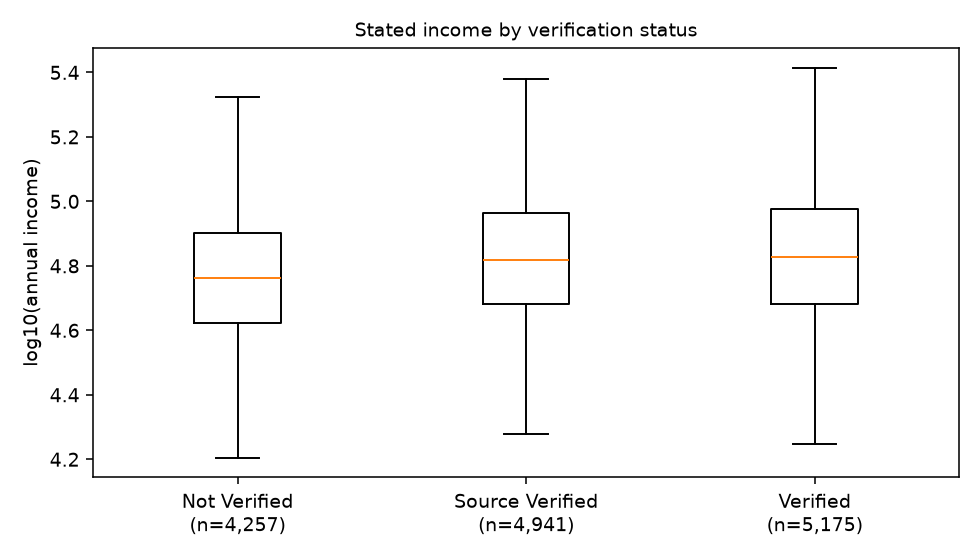

In [4]:
rows = {}
for status, d in fit.groupby("verification_status"):
    rows[status] = {"loans": len(d), "median income": d.annual_inc.median(), "p10": d.annual_inc.quantile(.10), "p90": d.annual_inc.quantile(.90),
                    "typed in thousands %": 100 * d.annual_inc_fixed.mean(),
                    "income above $200k %": 100 * (d.annual_inc > 200_000).mean(),
                    "rank corr. with credit limit": spearmanr(d.annual_inc, d.tot_hi_cred_lim)[0],
                    "default rate": d.defaulted.mean()}
inc = pd.DataFrame(rows).T
print(inc.round(3).to_string())
p = kruskal(*[d.annual_inc for _, d in fit.groupby("verification_status")]).pvalue
print(f"\nDo the three groups have different income distributions? Kruskal-Wallis p-value = {p:.2g}")
display(Image("reports/a3_reliability_evidence/figures/income_by_verification.png", width=800))

**Reading it.**
- **Verified incomes are higher** (median about $66-67k against $58k for "Not Verified"). The platform checks the incomes it is already unsure about or that are large, so "verified" does not mean "different kind of person".
- In **every** group, income moves together with the credit limits reported independently by the bureau (rank correlation about 0.55 to 0.57). Two sources telling the same story is evidence that the numbers are real.
- About 3% of incomes were typed in thousands in every group (so the error is not tied to verification), and they were repaired.
- **Verification is not a safety badge:** verified loans default *more* (19% against 13%), probably because the platform chooses whom to verify. This is why we never read "verified" as "safer".

**Rating: `annual_inc` is medium.** Believable and consistent, but self-reported.

## 3. Evidence: are `installment` and `dti` consistent with income? (bullet 1b)

If a stated income were wildly wrong, the numbers that depend on it would look impossible: a monthly payment bigger than the income, or a debt-to-income ratio unrelated to the debts.

In [5]:
rows = {}
for status, d in fit.groupby("verification_status"):
    monthly = d.annual_inc / 12
    inst_pct = 100 * d.installment / monthly
    rows[status] = {"median installment as % of monthly income": inst_pct.median(),
                    "installment above 40% of income (%)": 100 * (inst_pct > 40).mean(),
                    "installment above 100% of income (%)": 100 * (inst_pct > 100).mean(),
                    "rank corr. dti vs revolving balance/income": spearmanr(d.dti, d.revol_bal / d.annual_inc)[0]}
print(pd.DataFrame(rows).T.round(2).to_string())

                 median installment as % of monthly income  installment above 40% of income (%)  installment above 100% of income (%)  rank corr. dti vs revolving balance/income
Not Verified                                          6.34                                  0.0                                   0.0                                        0.39
Source Verified                                       7.79                                  0.0                                   0.0                                        0.36
Verified                                              8.73                                  0.0                                   0.0                                        0.44


**Reading it.**
- The monthly installment is a median of about 6-9% of monthly income and **never** above 40% in any group. After the repairs from notebook 01 there is no loan whose payment exceeds its income. So the stated incomes are plausible.
- `dti` rises with the revolving balance relative to income (correlation 0.36 to 0.44), as it should: people with more card debt compared with their pay have a higher debt ratio. So `dti` and income describe the same person consistently.
- `dti` is calculated by the platform *from* the stated income, so it is only as reliable as that income: **medium**. `installment` is calculated from amount, rate and term, so it is **high**.

## 4. Evidence: is missingness random, or related to default? (bullet 1c)

A blank can mean many things: forgot to fill in, not applicable, or a hint of risk. If blanks were linked to default, the blank itself would be a signal, and filling it silently would throw that signal away. We check, field by field: how many are missing, and does the default rate differ between loans with and without the value (**Fisher's exact test** gives a p-value: small, say under 0.05, means the difference is unlikely to be chance).

In [6]:
def missing_report(label, is_missing):
    m = is_missing.to_numpy()
    y = fit.defaulted.to_numpy()
    table = [[(y[m] == 1).sum(), (y[m] == 0).sum()], [(y[~m] == 1).sum(), (y[~m] == 0).sum()]]
    return {"field": label, "loans missing": int(m.sum()), "% missing": 100 * m.mean(),
            "default rate when missing": y[m].mean(), "default rate when present": y[~m].mean(), "p-value": fisher_exact(table)[1]}

tests = pd.DataFrame([
    missing_report("emp_length", fit.emp_length.isna()),
    missing_report("emp_title", fit.emp_title.isna()),
    missing_report("mths_since_last_delinq", fit.mths_since_last_delinq.isna()),
    missing_report("bc_util (blank in the bureau file)", joined.loc[fit.index, "bc_util"].isna()),
    missing_report("earliest_cr_line (corrupted date)", fit.earliest_cr_line_invalid),
]).round(4)
print(tests.to_string(index=False))

                             field  loans missing  % missing  default rate when missing  default rate when present  p-value
                        emp_length            686     4.7728                     0.1953                     0.1713   0.1083
                         emp_title            824     5.7330                     0.1881                     0.1715   0.2171
            mths_since_last_delinq           7424    51.6524                     0.1674                     0.1777   0.1068
bc_util (blank in the bureau file)            151     1.0506                     0.2119                     0.1720   0.1943
 earliest_cr_line (corrupted date)            133     0.9253                     0.1504                     0.1726   0.5650


**Reading it.** In every case the p-value is above 0.05 (the smallest is about 0.11): missing and present loans default at statistically similar rates. **Missingness is not a hidden risk signal.** The gaps in the rates (for example 19.5% against 17.1% for `emp_length`) are small compared with how much a rate can move by chance with only 686 blank loans.

*"Not related to default"* is only half of the question. The other half: **why** is it missing?

share missing, by verification status:
                     emp_length  emp_title
verification_status                       
Not Verified                0.0        0.2
Source Verified             2.4        3.6
Verified                   10.9       12.4

mths_since_last_delinq is missing for 7,424 loans (52%).
Of those, 99.8% have zero delinquencies in the last two years.

Can the blank be predicted from OTHER fields? (AUC of a model predicting 'is missing'; 0.5 = no pattern)
                            field  auc_predicting_missingness_from_other_fields  pct_missing_2013  pct_missing_2014
                        emp_title                                         0.834             6.057             5.541
                       emp_length                                         0.873             4.225             5.098
           mths_since_last_delinq                                         0.839            55.936            49.113
                          bc_util                      

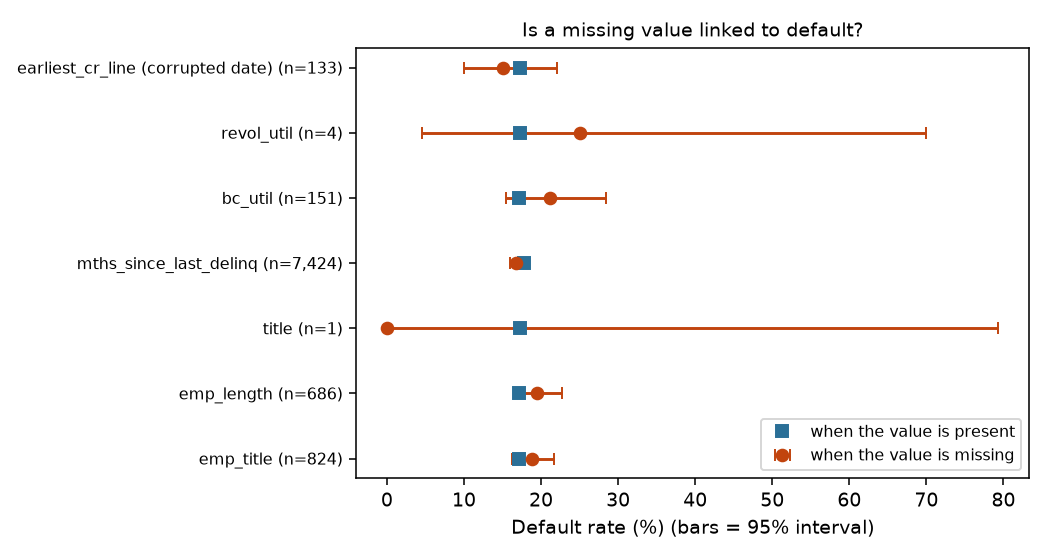

In [7]:
print("share missing, by verification status:")
print((fit.groupby("verification_status")[["emp_length", "emp_title"]].agg(lambda s: 100 * s.isna().mean())).round(1).to_string())

gap = fit[fit.mths_since_last_delinq.isna()]
print(f"\nmths_since_last_delinq is missing for {len(gap):,} loans ({100 * len(gap) / len(fit):.0f}%).")
print(f"Of those, {100 * (gap.delinq_2yrs == 0).mean():.1f}% have zero delinquencies in the last two years.")
print("\nCan the blank be predicted from OTHER fields? (AUC of a model predicting 'is missing'; 0.5 = no pattern)")
print(pd.read_csv("reports/a3_reliability_evidence/tables/missingness_mechanism.csv").round(3).to_string(index=False))
display(Image("reports/a3_reliability_evidence/figures/default_rate_when_missing.png", width=700))

**Reading it.**
- **`emp_length` and `emp_title`** are missing almost only among *verified* applicants (about 0% of unverified, 2% to 4% of source-verified, 11% to 12% of verified). The blank is tied to the **verification process**, not to the person's risk. A model predicts it from other fields with AUC 0.83 to 0.87, which confirms it follows a pattern.
- **`mths_since_last_delinq`** is missing for about 52% of loans once the historical zero code is recoded as missing (notebook 01), and almost all of them have **no delinquency at all** in the last two years. The blank means *"never delinquent"*, so it is **structural**, not forgotten. Filling it with an average would invent a delinquency date for someone who has none.
- **Corrupted credit dates** can't be predicted from other fields (AUC 0.495, a coin flip): the error is random, so the true date can't be recovered and we don't invent one.

**Decisions:** keep blanks as their own category or bin (WoE gives "missing" its own bin) instead of filling them silently. That's why `emp_length` is rated *medium* (large structural gap) and `mths_since_last_delinq` stays an input with its blank preserved.

## 5. Which columns were truly known at application time? (bullet 2)

The test is simple: **could the lender have known this value on the day it approved the loan?** Application fields and the bureau pull: yes. Anything recorded afterwards: no.

In [8]:
y = fit.defaulted.to_numpy()
def auc_alone(x):
    x = pd.Series(np.asarray(x, dtype=float))
    ok = x.notna().to_numpy()
    a = roc_auc_score(y[ok], x[ok])
    return max(a, 1 - a)

after = srv.set_index("id").reindex(fit.id)
scan = pd.DataFrame(
    [{"field": f, "known at application?": True, "AUC when used alone": auc_alone(fit[f])}
     for f in ["loan_amnt", "annual_inc", "dti", "fico_range_low", "revol_util", "inq_last_6mths", "tot_hi_cred_lim"]] +
    [{"field": f, "known at application?": False, "AUC when used alone": auc_alone(after[f])}
     for f in ["total_pymnt", "total_rec_prncp", "last_pymnt_amnt", "recoveries", "last_fico_range_high"]] +
    [{"field": "bureau_recovery_flag", "known at application?": False, "AUC when used alone": auc_alone(joined.set_index("id").reindex(fit.id).bureau_recovery_flag)}]
).round(3)
print(scan.to_string(index=False))

               field  known at application?  AUC when used alone
           loan_amnt                   True                0.538
          annual_inc                   True                0.552
                 dti                   True                0.574
      fico_range_low                   True                0.586
          revol_util                   True                0.546
      inq_last_6mths                   True                0.547
     tot_hi_cred_lim                   True                0.550
         total_pymnt                  False                0.723
     total_rec_prncp                  False                0.852
     last_pymnt_amnt                  False                0.780
          recoveries                  False                0.906
last_fico_range_high                  False                0.911
bureau_recovery_flag                  False                0.906


**Reading it.** A **leakage scan**: score every field by how well it predicts default alone. The honest application-time fields are all weak, about 0.54 to 0.59 here (as low as 0.51 for the weakest fields in the full scan). The post-issue fields are 0.72 to 0.91. A field that predicts that well is suspiciously good, and the reason is that it *records the outcome*: `recoveries` (money collected after the default), `total_rec_prncp` (how much principal was repaid), `last_fico_range_high` (a score pulled after the loan). **If a field looks too good, ask when it was recorded.**

The excluded columns, each with its reason:

In [9]:
excluded = cat[(~cat.known_at_application) & (cat.role != "target")][["field", "source", "reason"]]
print(excluded.to_string(index=False))

               field         source                                                                                                                                                                                                                          reason
bureau_recovery_flag  credit_bureau                                                       Leak: identical to `recoveries > 0` in the servicing file (4,207 of 4,207 loans), and every flagged loan defaulted (single-field AUC 0.91). Always 0 in the 2016 holdout.
         total_pymnt loan_servicing                             Recorded after the loan was issued; not known when the applicant applies. Payments made so far reveal the outcome. Alone it predicts default with AUC 0.72 (application-time fields: 0.51 to 0.59).
     total_rec_prncp loan_servicing                                Recorded after the loan was issued; not known when the applicant applies. Principal repaid reveals the outcome. Alone it predicts default with AUC 0.85 (

**Decision:** every `loan_servicing` column and `bureau_recovery_flag` are **excluded from the model**. They are kept only for the label audit (notebook 01). The `last_fico_range_*` columns look like the application-time FICO but are a *later* pull, so they would have fooled a less careful reader.

## 5b. A special case: the platform's own grade, sub-grade and interest rate

These *are* known at application time, so they are not leaks. But the brief says they are *"the platform's own pricing, set from its existing risk model"*. A new model that uses them partly **copies the old model**. We measure how much they add before deciding.

In [10]:
print(pd.read_csv("reports/a3_platform_score_check/tables/auc_by_input_set.csv").round(3).to_string(index=False))

                input_set   auc  auc_ci_low  auc_ci_high
           sub_grade_only 0.697       0.678        0.717
            int_rate_only 0.696       0.677        0.714
               our_inputs 0.708       0.691        0.726
our_inputs_plus_sub_grade 0.712       0.695        0.732


**Reading it.** The platform's sub-grade alone ranks defaulters about as well as the rate alone (about 0.70). Our own fields, without any platform score, reach about the same (0.708). Adding the sub-grade on top gains only about 0.004 in this simple test, and the intervals overlap heavily. (The careful comparison in Part B, with a scorecard and time-ordered folds, finds a somewhat larger gain of about 0.01. Neither test is large, which is why the decision rests on a rule fixed beforehand and not on one number.)

**Decision for Part A:** keep `grade`, `sub_grade` and `int_rate` in the contract, **flagged as platform scores**, so the model engineer can use them as a benchmark ("does the model beat the grade alone?") and test them as an input. We try both in Part B and choose by a rule fixed beforehand (see `DESIGN.md`).

## 6. Build application-time features (bullet 3)

A **feature** is a column we compute from the raw fields to express something a credit officer would care about. All of these use only information available at application time, and nothing is learned from the default outcome when building them.

In [11]:
feats = FeatureBuilder().fit(clean).transform(fit)
rows = []
for f in FEATURE_FIELDS:
    s = feats[f]
    rows.append({"feature": f, "definition": DEFINITIONS[f], "missing": int(s.isna().sum()), "median": s.median(),
                 "min": s.min(), "max": s.max(), "skew": s.skew(), "AUC alone": auc_alone(s)})
summary = pd.DataFrame(rows).round(3)
print(summary.drop(columns=["definition"]).to_string(index=False))
print()
for r in summary.itertuples():
    print(f"{r.feature:24s} = {r.definition}")

              feature  missing  median     min     max  skew  AUC alone
credit_history_months      133 179.000  37.000 765.000 1.091      0.531
       loan_to_income        0   0.208   0.002   0.500 0.345      0.591
installment_to_income        0   0.077   0.001   0.223 0.469      0.575
  revol_bal_to_income        0   0.195   0.000   4.335 4.112      0.527
             fico_mid        0 687.000 662.000 842.000 1.425      0.586
       open_acc_share        0   0.467   0.045   1.000 0.569      0.536
recent_accounts_share        0   0.160   0.000   0.929 1.386      0.587

credit_history_months    = months from the first credit line to the loan issue date
loan_to_income           = loan amount divided by annual income
installment_to_income    = monthly installment divided by monthly income
revol_bal_to_income      = revolving balance divided by annual income
fico_mid                 = midpoint of the FICO range
open_acc_share           = open accounts divided by total accounts
recent_acco

**Why each feature, in plain words**

| Feature | The question it answers |
|---|---|
| `credit_history_months` | How long has this person had credit? (a longer track record, more experience) |
| `loan_to_income` | How big is this loan compared with a year of pay? |
| `installment_to_income` | How much of each month's pay would this payment take? |
| `revol_bal_to_income` | How large is the card debt compared with income? |
| `fico_mid` | One FICO number instead of a low-high band |
| `open_acc_share` | What share of all the accounts they've ever had is still open? |
| `recent_accounts_share` | What share of their accounts is brand new? (borrowing a lot lately) |

**Reading it.** Each feature on its own is a weak ranker (0.52 to 0.59). The loan-size features and `fico_mid`, `recent_accounts_share` are the strongest. That's normal for credit data: no single field decides. `credit_history_months` is missing for 133 fit-window loans, exactly the 133 corrupted credit dates, so those are left blank and flagged, never invented. Credit history length ends up weaker than a textbook would predict (information value about 0.014 in the WoE ranking, which a later notebook explains); in this data it carries little signal, so we don't claim otherwise.

The decile chart below sorts loans into ten groups by each feature (1 = lowest) and shows the default rate in each, with 95% intervals. A real signal slopes steadily.

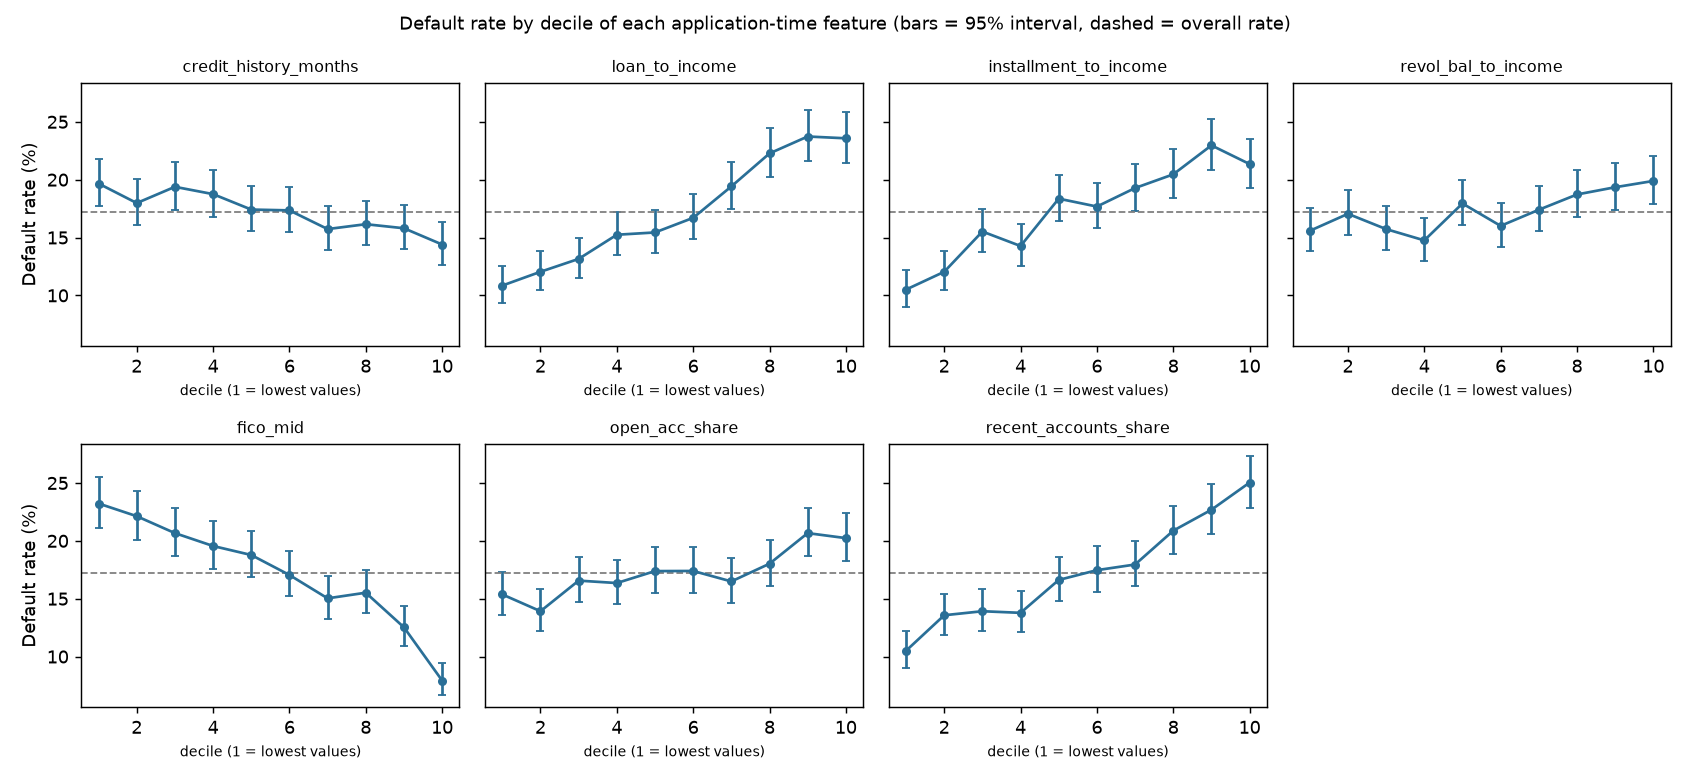

In [12]:
display(Image("reports/a3_feature_evidence/figures/default_rate_by_decile.png", width=950))

## Summary: what the brief asked, and where it is answered

| Brief item | Answered in |
|---|---|
| Every field rated high / medium / low, with evidence | section 1 (and `docs/field_reliability.md`, the spec) |
| `annual_inc` across `verification_status` | section 2 |
| `installment` and `dti` consistent with income | section 3 |
| Missingness random or related to default | section 4 |
| Which columns were known at application time, and why exclude the rest | section 5 |
| Application-time features | section 6 |
| Platform grade / interest rate decision | section 5b |